# Shords Dataset Analysis


In [ ]:
# Run this if you need to download the data
%pip install kagglehub

In [ ]:
# Data can be loaded through kagglehub api
import kagglehub

major_minor_triad_dataset = kagglehub.dataset_download("mehanat96/major-vs-minor-guitar-chords")
major_minor_guitar_piano_dataset = kagglehub.dataset_download("deepcontractor/musical-instrument-chord-classification")

In [17]:
import sys
sys.path.insert(0, '..')

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display
from pathlib import Path
import pandas as pd

In [18]:
DATA_DIR = Path('../data/shords_dataset')

major_files = sorted(list((DATA_DIR / 'major').glob('*.wav')))
minor_files = sorted(list((DATA_DIR / 'minor').glob('*.wav')))

print(f'Major chords: {len(major_files)}')
print(f'Minor chords: {len(minor_files)}')
print(f'Total: {len(major_files) + len(minor_files)}')

Major chords: 250
Minor chords: 252
Total: 502


     count      mean       std       min       25%       50%       75%  \
maj  250.0  2.551092  0.999902  1.214558  1.787846  2.234841  3.111927   
min  252.0  1.919533  0.542304  0.808299  1.554518  1.758197  2.163747   

          max  
maj  6.350658  
min  4.226032  


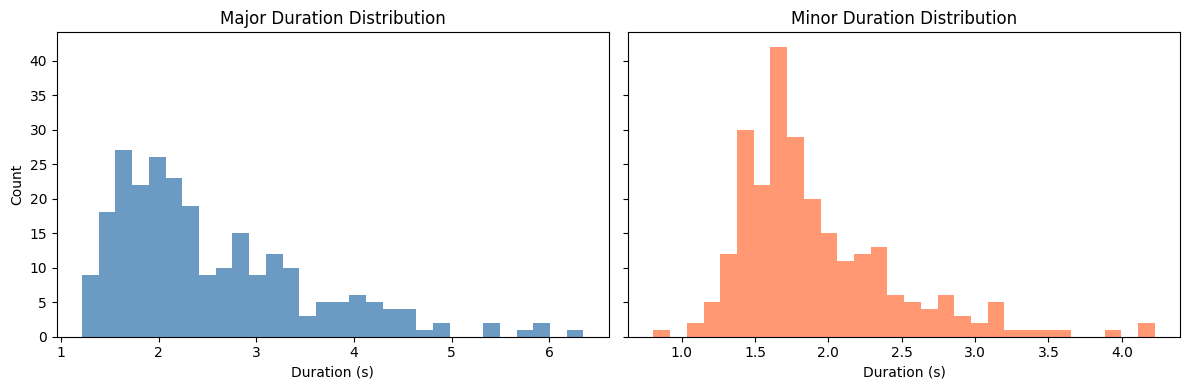

In [20]:
def durations_for_files(files):
    durations = []
    for f in files:
        y, sr = librosa.load(str(f), sr=None)
        durations.append(librosa.get_duration(y=y, sr=sr))
    return np.array(durations)

major_durations = durations_for_files(major_files)
minor_durations = durations_for_files(minor_files)

report = pd.DataFrame({
    'maj': pd.Series(major_durations),
    'min': pd.Series(minor_durations)
})

print(report.describe().T)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
axes[0].hist(major_durations, bins=30, alpha=0.8, color='steelblue')
axes[0].set_title('Major Duration Distribution')
axes[0].set_xlabel('Duration (s)')
axes[0].set_ylabel('Count')

axes[1].hist(minor_durations, bins=30, alpha=0.8, color='coral')
axes[1].set_title('Minor Duration Distribution')
axes[1].set_xlabel('Duration (s)')

plt.tight_layout()
plt.show()

We see that the duration of the audio files varies a lot, so we may need to normalize the data. The other dataset has all of its files around 2 seconds, so we will truncate and pad files to 2 seconds when training the model.

### Sample rate for all files

In [5]:
def get_sample_rates(files):
    rates = []
    for f in files:
        rates.append(librosa.get_samplerate(str(f)))
    return np.array(rates)

major_sample_rates = get_sample_rates(major_files)
minor_sample_rates = get_sample_rates(minor_files)

sr_counts = pd.DataFrame({
    'Major': pd.Series(major_sample_rates).value_counts(),
    'Minor': pd.Series(minor_sample_rates).value_counts()
}).fillna(0).astype(int)

print("Sample Rate Counts (Hz):")
print(sr_counts)

Sample Rate Counts (Hz):
       Major  Minor
44100    250    252


The sample rate is consistent across all files. We can even cut it in half to 22100 Hz without losing much information and for easier computation.

### Class Distribution

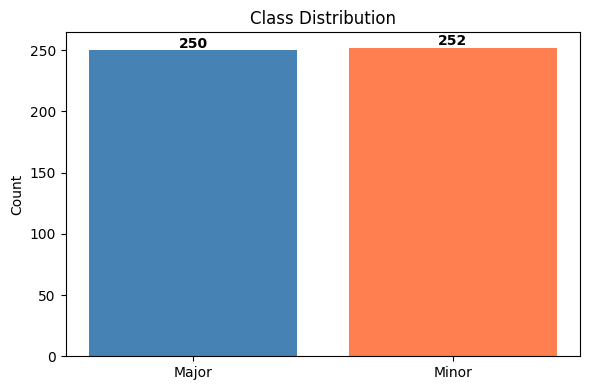

In [6]:
labels = ['Major'] * len(major_files) + ['Minor'] * len(minor_files)

fig, ax = plt.subplots(figsize=(6, 4))
unique, counts = np.unique(labels, return_counts=True)
ax.bar(unique, counts, color=['steelblue', 'coral'])
for i, (u, c) in enumerate(zip(unique, counts)):
    ax.text(i, c + 2, str(c), ha='center', fontweight='bold')
ax.set_ylabel('Count')
ax.set_title('Class Distribution')
plt.tight_layout()
plt.show()

Both classes are balanced in this set, which is good, because it wont introduce bias in the model.

### Waveform from the two datasets

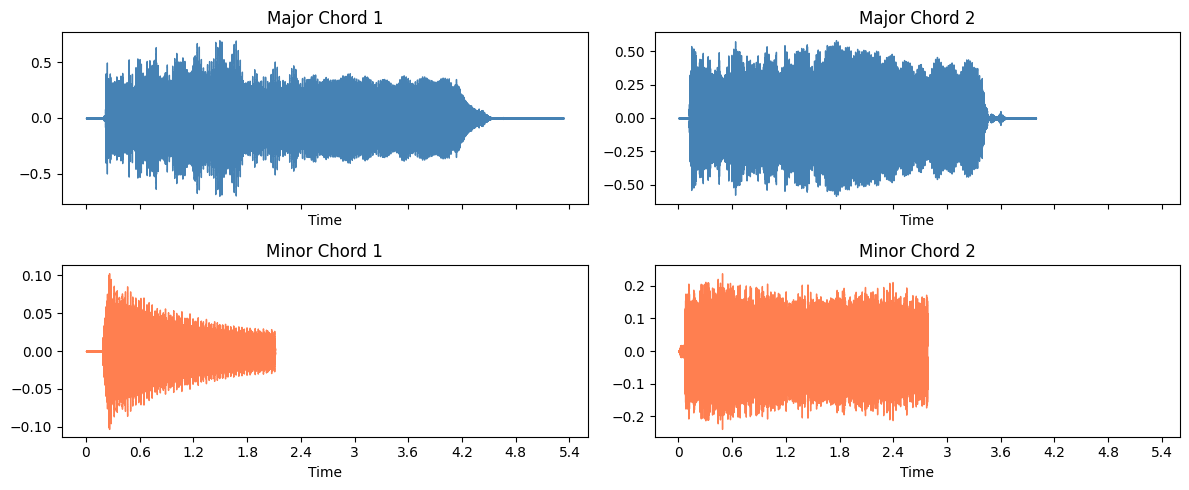

In [7]:
SR = 22050

y_maj, sr = librosa.load(str(major_files[0]), sr=SR)
y_min, _ = librosa.load(str(minor_files[0]), sr=SR)
y_maj2, _ = librosa.load(str(major_files[5]), sr=SR)
y_min2, _ = librosa.load(str(minor_files[5]), sr=SR)

fig, axes = plt.subplots(2, 2, figsize=(12, 5), sharex=True)
librosa.display.waveshow(y_maj, sr=sr, ax=axes[0][0], color='steelblue')
axes[0][0].set_title('Major Chord 1')
librosa.display.waveshow(y_min, sr=sr, ax=axes[1][0], color='coral')
axes[1][0].set_title('Minor Chord 1')
librosa.display.waveshow(y_maj2, sr=sr, ax=axes[0][1], color='steelblue')
axes[0][1].set_title('Major Chord 2')
librosa.display.waveshow(y_min2, sr=sr, ax=axes[1][1], color='coral')
axes[1][1].set_title('Minor Chord 2')
plt.tight_layout()
plt.show()

Clearly seeing the padding, introduced by the normalization librosa introduced on shorter than 2 seconds

### Mel Spectrogram

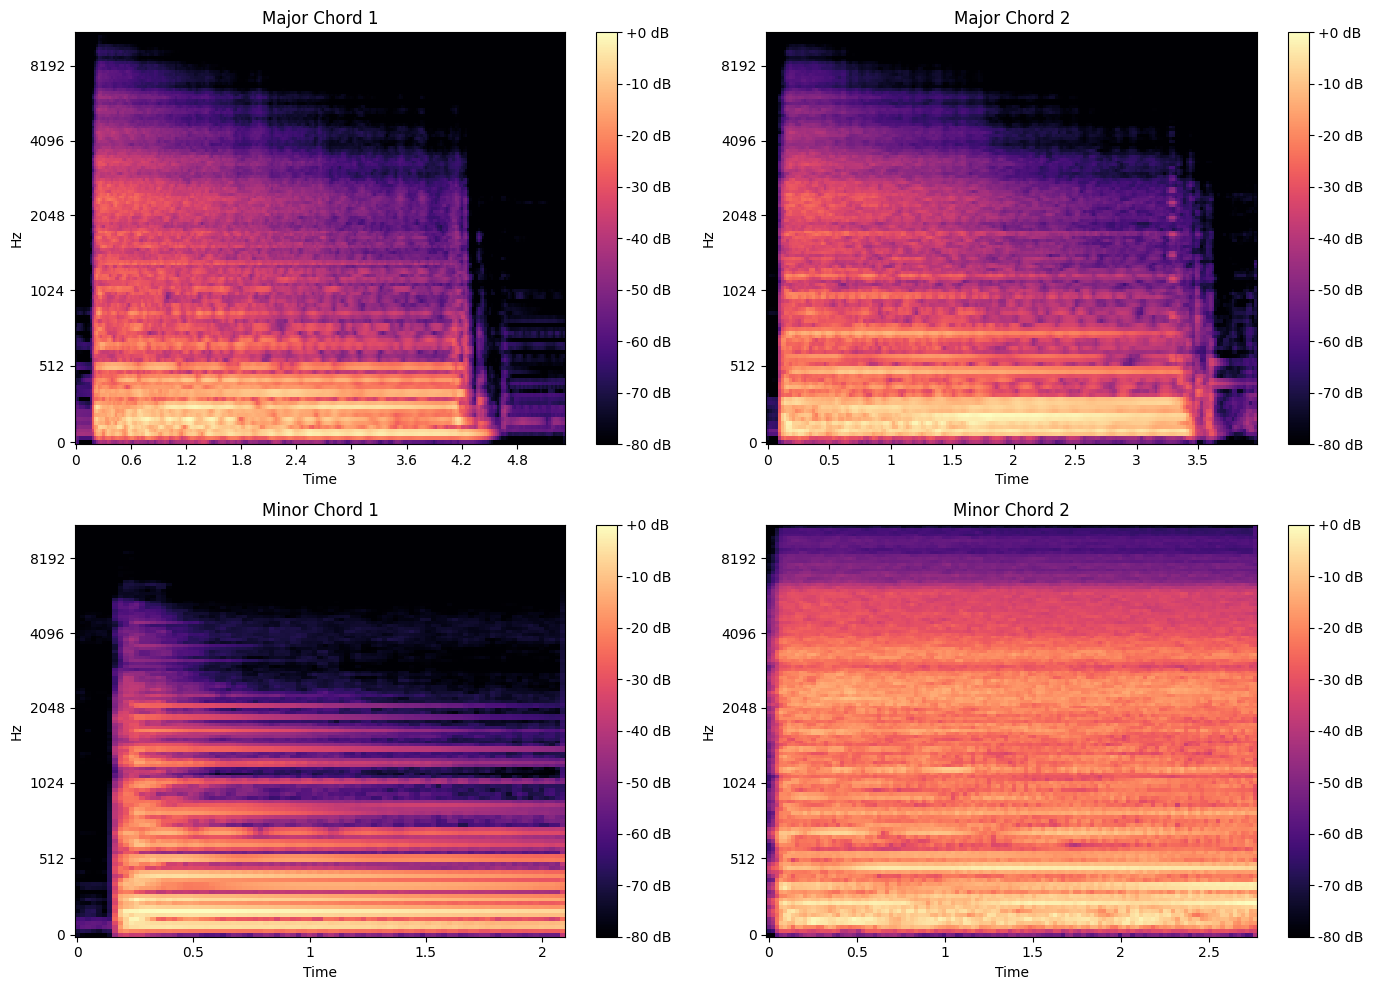

In [8]:
mel_maj = librosa.feature.melspectrogram(y=y_maj, sr=sr, n_mels=128)
mel_min = librosa.feature.melspectrogram(y=y_min, sr=sr, n_mels=128)
mel_maj_db = librosa.power_to_db(mel_maj, ref=np.max)
mel_min_db = librosa.power_to_db(mel_min, ref=np.max)

mel_maj2 = librosa.feature.melspectrogram(y=y_maj2, sr=sr, n_mels=128)
mel_min2 = librosa.feature.melspectrogram(y=y_min2, sr=sr, n_mels=128)
mel_maj_db2 = librosa.power_to_db(mel_maj2, ref=np.max)
mel_min_db2 = librosa.power_to_db(mel_min2, ref=np.max)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
img0 = librosa.display.specshow(mel_maj_db, sr=sr, x_axis='time', y_axis='mel', ax=axes[0][0])
axes[0][0].set_title('Major Chord 1')
fig.colorbar(img0, ax=axes[0][0], format='%+2.0f dB')

img1 = librosa.display.specshow(mel_min_db, sr=sr, x_axis='time', y_axis='mel', ax=axes[1][0])
axes[1][0].set_title('Minor Chord 1')
fig.colorbar(img1, ax=axes[1][0], format='%+2.0f dB')

img2 = librosa.display.specshow(mel_maj_db2, sr=sr, x_axis='time', y_axis='mel', ax=axes[0][1])
axes[0][1].set_title('Major Chord 2')
fig.colorbar(img2, ax=axes[0][1], format='%+2.0f dB')

img3 = librosa.display.specshow(mel_min_db2, sr=sr, x_axis='time', y_axis='mel', ax=axes[1][1])
axes[1][1].set_title('Minor Chord 2')
fig.colorbar(img3, ax=axes[1][1], format='%+2.0f dB')

plt.tight_layout()
plt.show()

### Chromagram

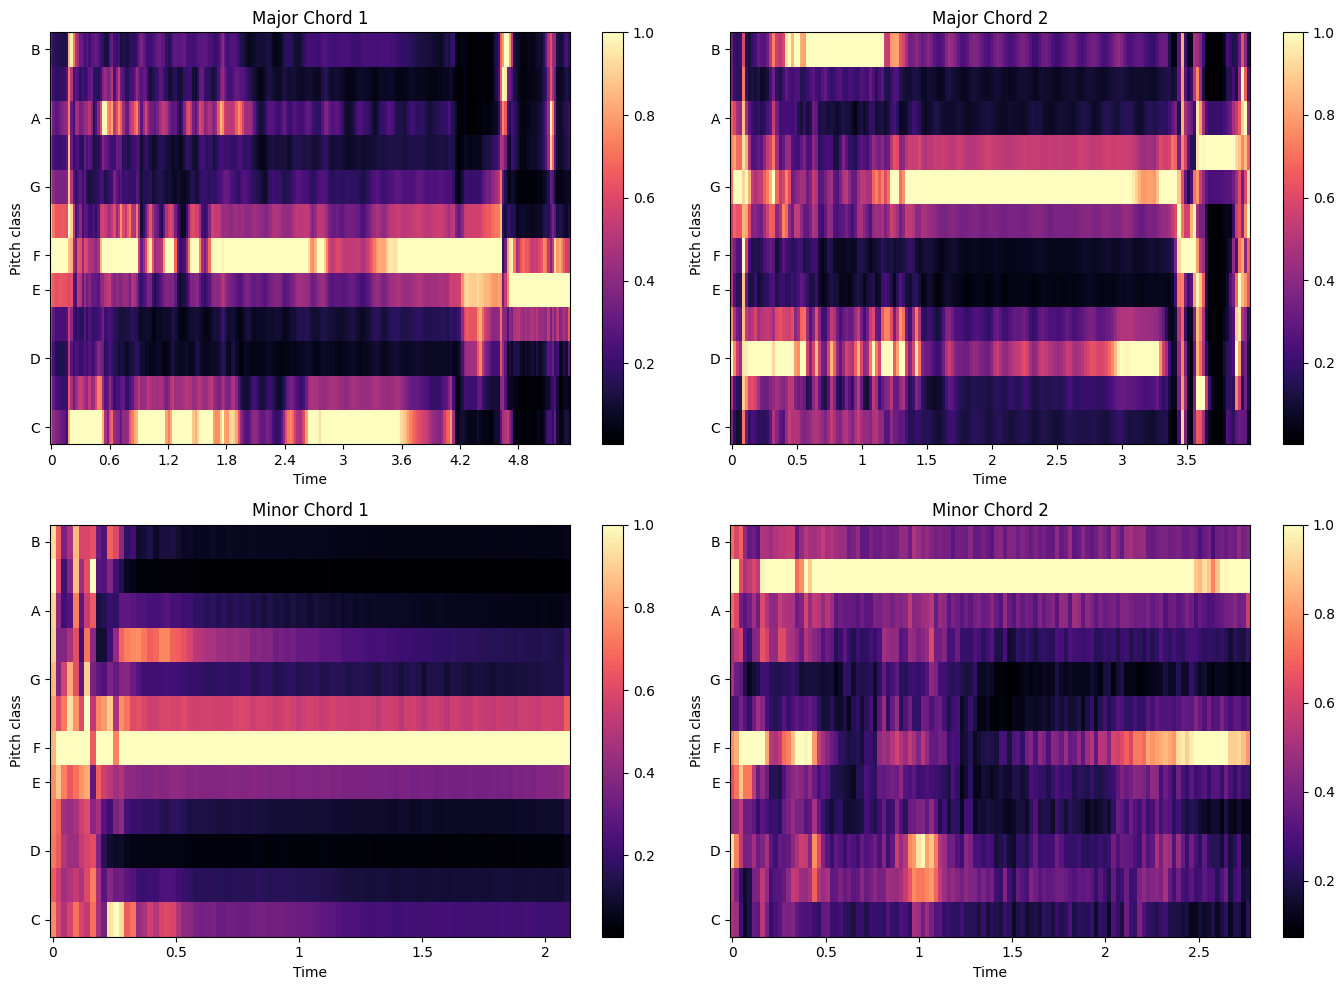

In [9]:
chroma_maj = librosa.feature.chroma_stft(y=y_maj, sr=sr)
chroma_min = librosa.feature.chroma_stft(y=y_min, sr=sr)
chroma_maj2 = librosa.feature.chroma_stft(y=y_maj2, sr=sr)
chroma_min2 = librosa.feature.chroma_stft(y=y_min2, sr=sr)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
img0 = librosa.display.specshow(chroma_maj, sr=sr, x_axis='time', y_axis='chroma', ax=axes[0][0])
axes[0][0].set_title('Major Chord 1')
fig.colorbar(img0, ax=axes[0][0])

img1 = librosa.display.specshow(chroma_min, sr=sr, x_axis='time', y_axis='chroma', ax=axes[1][0])
axes[1][0].set_title('Minor Chord 1')
fig.colorbar(img1, ax=axes[1][0])

img2 = librosa.display.specshow(chroma_maj2, sr=sr, x_axis='time', y_axis='chroma', ax=axes[0][1])
axes[0][1].set_title('Major Chord 2')
fig.colorbar(img2, ax=axes[0][1])

img3 = librosa.display.specshow(chroma_min2, sr=sr, x_axis='time', y_axis='chroma', ax=axes[1][1])
axes[1][1].set_title('Minor Chord 2')
fig.colorbar(img3, ax=axes[1][1])
plt.tight_layout()
plt.show()

### MFCCs

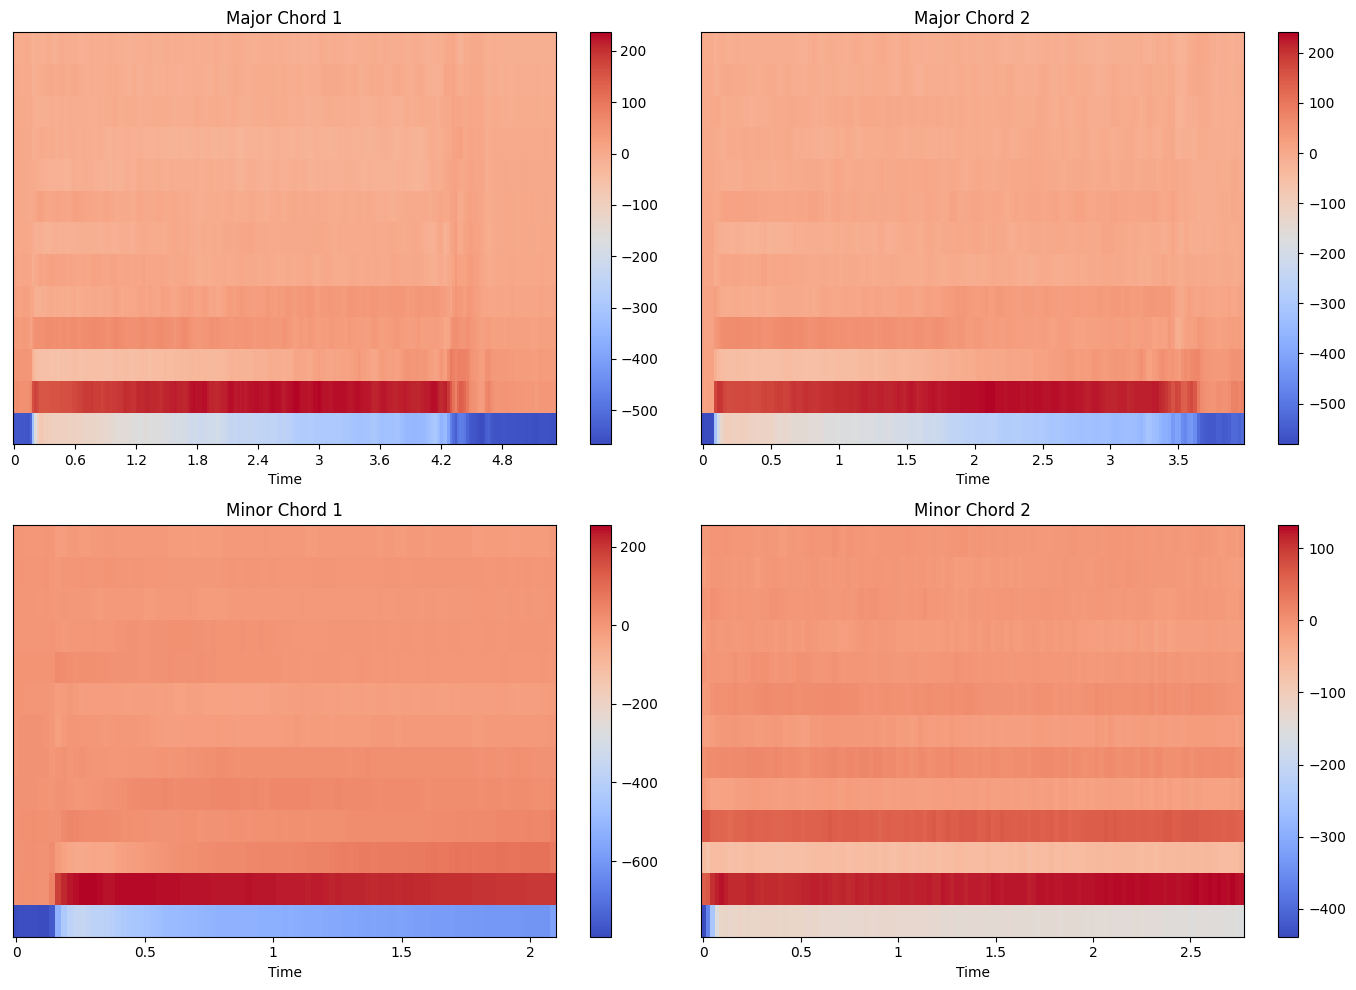

In [10]:
mfcc_maj = librosa.feature.mfcc(y=y_maj, sr=sr, n_mfcc=13)
mfcc_min = librosa.feature.mfcc(y=y_min, sr=sr, n_mfcc=13)
mfcc_maj2 = librosa.feature.mfcc(y=y_maj2, sr=sr, n_mfcc=13)
mfcc_min2 = librosa.feature.mfcc(y=y_min2, sr=sr, n_mfcc=13)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
img0 = librosa.display.specshow(mfcc_maj, sr=sr, x_axis='time', ax=axes[0][0])
axes[0][0].set_title('Major Chord 1')
fig.colorbar(img0, ax=axes[0][0])

img1 = librosa.display.specshow(mfcc_maj2, sr=sr, x_axis='time', ax=axes[0][1])
axes[0][1].set_title('Major Chord 2')
fig.colorbar(img1, ax=axes[0][1])

img2 = librosa.display.specshow(mfcc_min, sr=sr, x_axis='time', ax=axes[1][0])
axes[1][0].set_title('Minor Chord 1')
fig.colorbar(img2, ax=axes[1][0])

img3 = librosa.display.specshow(mfcc_min2, sr=sr, x_axis='time', ax=axes[1][1])
axes[1][1].set_title('Minor Chord 2')
fig.colorbar(img3, ax=axes[1][1])

plt.tight_layout()
plt.show()

### Mean Chroma Profile

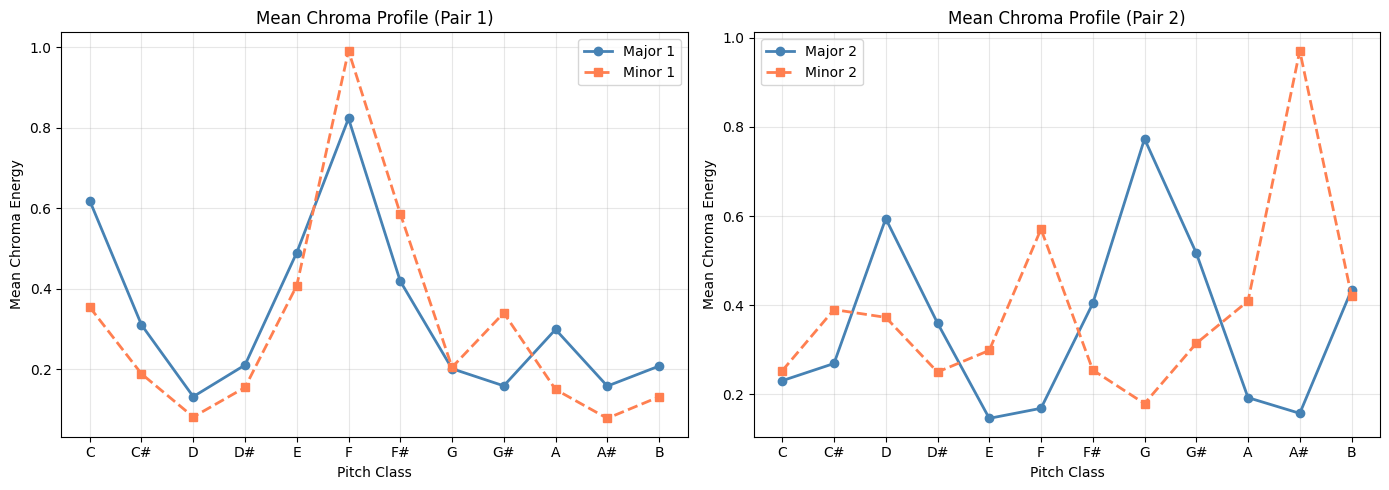

In [11]:
pitch_classes = ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(pitch_classes, np.mean(chroma_maj, axis=1), 'o-', color='steelblue', linewidth=2, label='Major 1')
axes[0].plot(pitch_classes, np.mean(chroma_min, axis=1), 's--', color='coral', linewidth=2, label='Minor 1')
axes[0].set_xlabel('Pitch Class')
axes[0].set_ylabel('Mean Chroma Energy')
axes[0].set_title('Mean Chroma Profile (Pair 1)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(pitch_classes, np.mean(chroma_maj2, axis=1), 'o-', color='steelblue', linewidth=2, label='Major 2')
axes[1].plot(pitch_classes, np.mean(chroma_min2, axis=1), 's--', color='coral', linewidth=2, label='Minor 2')
axes[1].set_xlabel('Pitch Class')
axes[1].set_ylabel('Mean Chroma Energy')
axes[1].set_title('Mean Chroma Profile (Pair 2)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Full Stats

In [12]:
from src.features import extract_chroma, extract_mfcc

all_chroma_maj, all_chroma_min = [], []
all_mfcc_maj, all_mfcc_min = [], []
rms_maj, rms_min = [], []
durations_maj_full, durations_min_full = [], []

for f in major_files:
    y_tmp, sr_tmp = librosa.load(str(f), sr=SR)
    durations_maj_full.append(len(y_tmp) / sr_tmp)
    rms_maj.append(np.sqrt(np.mean(y_tmp**2)))
    all_chroma_maj.append(extract_chroma(y_tmp, sr_tmp))
    all_mfcc_maj.append(extract_mfcc(y_tmp, sr_tmp))

for f in minor_files:
    y_tmp, sr_tmp = librosa.load(str(f), sr=SR)
    durations_min_full.append(len(y_tmp) / sr_tmp)
    rms_min.append(np.sqrt(np.mean(y_tmp**2)))
    all_chroma_min.append(extract_chroma(y_tmp, sr_tmp))
    all_mfcc_min.append(extract_mfcc(y_tmp, sr_tmp))

all_chroma_maj = np.array(all_chroma_maj)
all_chroma_min = np.array(all_chroma_min)
all_mfcc_maj = np.array(all_mfcc_maj)
all_mfcc_min = np.array(all_mfcc_min)

In [23]:
stats = {
    'Metric': ['Count', 'Duration (mean)', 'Duration (std)', 'RMS (mean)', 'RMS (std)',
               'Chroma mean (mean)', 'Chroma mean (std)', 'MFCC mean (mean)', 'MFCC mean (std)'],
    'Major': [
        len(major_files),
        f'{np.mean(durations_maj_full):.3f}s',
        f'{np.std(durations_maj_full):.4f}s',
        f'{np.mean(rms_maj):.4f}',
        f'{np.std(rms_maj):.4f}',
        f'{np.mean(all_chroma_maj):.4f}',
        f'{np.std(all_chroma_maj):.4f}',
        f'{np.mean(all_mfcc_maj):.2f}',
        f'{np.std(all_mfcc_maj):.2f}',
    ],
    'Minor': [
        len(minor_files),
        f'{np.mean(durations_min_full):.3f}s',
        f'{np.std(durations_min_full):.4f}s',
        f'{np.mean(rms_min):.4f}',
        f'{np.std(rms_min):.4f}',
        f'{np.mean(all_chroma_min):.4f}',
        f'{np.std(all_chroma_min):.4f}',
        f'{np.mean(all_mfcc_min):.2f}',
        f'{np.std(all_mfcc_min):.2f}',
    ],
}

df_stats = pd.DataFrame(stats).T
df_stats

,0,1,2,3,4,5,6,7,8
Metric,Count,Duration (mean),Duration (std),RMS (mean),RMS (std),Chroma mean (mean),Chroma mean (std),MFCC mean (mean),MFCC mean (std)
Major,250,2.551s,0.9979s,0.1025,0.0509,0.2793,0.2601,-16.64,109.57
Minor,252,1.920s,0.5412s,0.0977,0.0448,0.2798,0.2622,-16.32,110.95


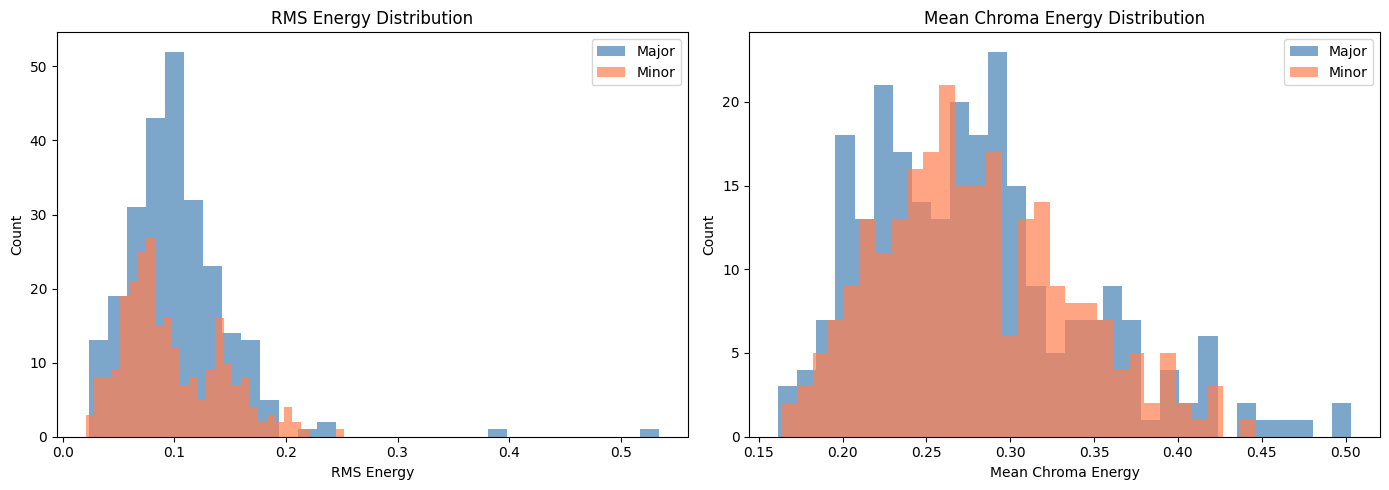

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(rms_maj, bins=30, alpha=0.7, color='steelblue', label='Major')
axes[0].hist(rms_min, bins=30, alpha=0.7, color='coral', label='Minor')
axes[0].set_xlabel('RMS Energy')
axes[0].set_ylabel('Count')
axes[0].set_title('RMS Energy Distribution')
axes[0].legend()

all_chroma_mean_maj = np.mean(all_chroma_maj, axis=1)
all_chroma_mean_min = np.mean(all_chroma_min, axis=1)
axes[1].hist(all_chroma_mean_maj, bins=30, alpha=0.7, color='steelblue', label='Major')
axes[1].hist(all_chroma_mean_min, bins=30, alpha=0.7, color='coral', label='Minor')
axes[1].set_xlabel('Mean Chroma Energy')
axes[1].set_ylabel('Count')
axes[1].set_title('Mean Chroma Energy Distribution')
axes[1].legend()

plt.tight_layout()
plt.show()

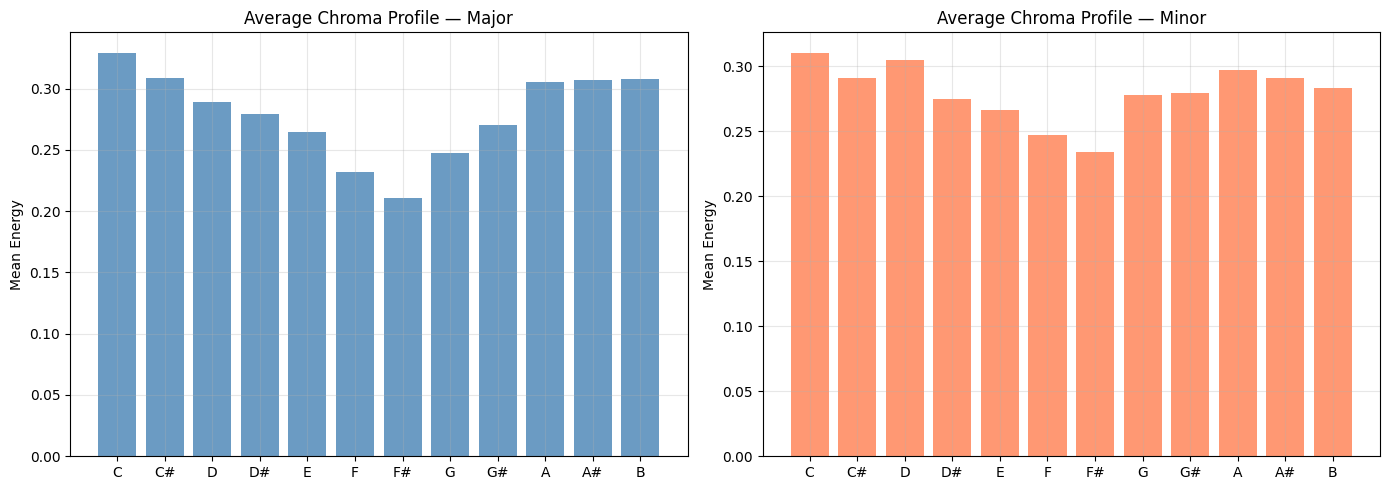

In [15]:
pitch_classes = ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

mean_chroma_maj = np.mean(all_chroma_maj, axis=0)
mean_chroma_min = np.mean(all_chroma_min, axis=0)
axes[0].bar(pitch_classes, mean_chroma_maj, color='steelblue', alpha=0.8)
axes[0].set_ylabel('Mean Energy')
axes[0].set_title('Average Chroma Profile — Major')
axes[0].grid(True, alpha=0.3)

axes[1].bar(pitch_classes, mean_chroma_min, color='coral', alpha=0.8)
axes[1].set_ylabel('Mean Energy')
axes[1].set_title('Average Chroma Profile — Minor')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Again, these stats do not give much information about the features. Even more, we see the Average Chroma Profile here is high everywhere. This might be due to the fact that most data is recorded with a distortion guitar, which has a lot of harmonics and brings additional noise. We need to reduce the noise in the data and filter the peaks with an appropriate threshhold.